
# Health Insurance Customer Vehicle Insurance Cross-Sell Analysis

## 1. Business Understanding

### Business Context
An insurance company has an existing health insurance customer base and wants to identify customers who may be interested in purchasing vehicle insurance.

### Business Objective
Analyze customer characteristics and historical responses to understand which customer segments are more likely to respond positively to a vehicle insurance offer.

### Key Business Questions
- What percentage of customers responded positively?
- Does response rate differ by age group?
- Does previous vehicle insurance affect customer response?
- How does vehicle damage history relate to response?
- Do vehicle age and annual premium relate to response?
- Which sales channels have higher response rates?

### Target Variable
`Response`

- `0` — No positive response
- `1` — Positive response

### Important Limitation
This analysis identifies associations in historical data. It does not prove that a customer characteristic causes a positive response.


In [1]:
# Check whether Python is working correctly

print("Health Insurance Cross-Sell Analysis")
print("Python environment is ready!")

Health Insurance Cross-Sell Analysis
Python environment is ready!


In [5]:
%pip install matplotlib seaborn pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
from pathlib import Path

csv_path = Path("../data/train.csv")

print("File exists:", csv_path.exists())
print("File size:", csv_path.stat().st_size, "bytes")

File exists: True
File size: 0 bytes


In [11]:
# Load the original dataset
df = pd.read_csv("../data/train.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [12]:
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [13]:
print(df.shape)

(381109, 12)


In [14]:
print("Rows:", df.shape[0])

Rows: 381109


In [15]:
print("Columns:", df.shape[1])

Columns: 12


In [16]:
# Inspect column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  str    
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  str    
 7   Vehicle_Damage        381109 non-null  str    
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 40.5 MB


In [17]:
# Display all column names
df.columns.tolist()

['id',
 'Gender',
 'Age',
 'Driving_License',
 'Region_Code',
 'Previously_Insured',
 'Vehicle_Age',
 'Vehicle_Damage',
 'Annual_Premium',
 'Policy_Sales_Channel',
 'Vintage',
 'Response']

#Check missing values

In [18]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": (missing_values / len(df)) * 100
})

display(missing_summary)

,Missing Values,Missing Percentage (%)
id,0,0.0
Gender,0,0.0
Age,0,0.0
Driving_License,0,0.0
Region_Code,0,0.0
Previously_Insured,0,0.0
Vehicle_Age,0,0.0
Vehicle_Damage,0,0.0
Annual_Premium,0,0.0
Policy_Sales_Channel,0,0.0


#Check duplicate records

In [19]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


Check data types

In [20]:
# Review data types

display(df.dtypes)

id                        int64
Gender                      str
Age                       int64
Driving_License           int64
Region_Code             float64
Previously_Insured        int64
Vehicle_Age                 str
Vehicle_Damage              str
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                   int64
Response                  int64
dtype: object

Understand the target variable

In [21]:
# Count customers in each response category
response_counts = df["Response"].value_counts().sort_index()

display(response_counts)

Response
0    334399
1     46710
Name: count, dtype: int64

In [22]:
# Calculate response percentages
response_percentages = (
    df["Response"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(response_percentages.round(2))

Response
0    87.74
1    12.26
Name: proportion, dtype: float64

In [23]:
# Summarize customer response

response_summary = pd.DataFrame({
    "Customer Count": df["Response"].value_counts().sort_index(),
    "Percentage (%)": df["Response"].value_counts(normalize=True).sort_index() * 100
})

response_summary.index = ["No Positive Response (0)", "Positive Response (1)"]

display(response_summary.round(2))

,Customer Count,Percentage (%)
No Positive Response (0),334399,87.74
Positive Response (1),46710,12.26


Only 12.26% of customers responded positively to the vehicle insurance offer, while 87.74% did not.

This indicates a class imbalance: positive responses are much less common than negative responses.

Why this matters:
- A campaign aimed at every customer may have limited effectiveness.
- Accuracy alone may be misleading when we later evaluate machine learning models.
- We should analyze response rates by customer segment to identify potentially promising groups.
This is an observed response rate, not proof that a targeted campaign will increase sales.

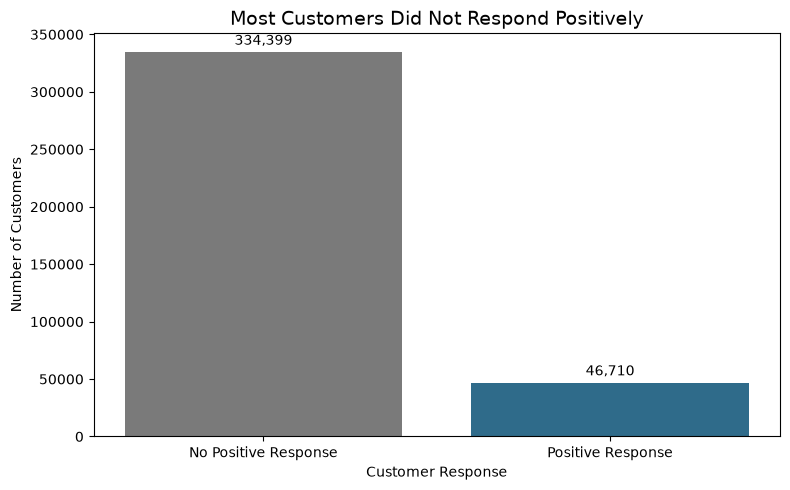

In [24]:
# Visualize the distribution of customer responses

response_labels = ["No Positive Response", "Positive Response"]
response_values = df["Response"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    response_labels,
    response_values,
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Most Customers Did Not Respond Positively", fontsize=14)
plt.xlabel("Customer Response")
plt.ylabel("Number of Customers")

plt.bar_label(
    bars,
    labels=[f"{value:,}" for value in response_values],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Overall Customer Response

Only 12.26% of customers (46,710 out of 381,109) responded positively to the vehicle insurance offer, while 87.74% did not.

The response distribution is imbalanced, with the majority of customers not responding positively. Therefore, future analysis should focus on response rates across customer segments rather than relying only on raw customer counts.

**Business implication:** Customer segmentation may help identify groups with relatively higher response rates. However, the current analysis does not establish causality or guarantee improved campaign performance.


Create age groups

In [25]:
# Group customers into age segments

age_bins = [0, 25, 35, 45, 55, 65, 100]
age_labels = [
    "18–25",
    "26–35",
    "36–45",
    "46–55",
    "56–65",
    "66+"
]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

df[["Age", "Age_Group"]].head(10)

,Age,Age_Group
0,44,36–45
1,76,66+
2,47,46–55
3,21,18–25
4,29,26–35
5,24,18–25
6,23,18–25
7,56,56–65
8,24,18–25
9,32,26–35


Calculate response rate by age group

In [26]:
# Calculate customer count and positive response rate by age group

age_analysis = df.groupby("Age_Group", observed=False).agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

age_analysis["Response_Rate"] = age_analysis["Response_Rate"] * 100

display(age_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Age_Group,,,
18–25,114505,4047,3.53
26–35,72307,8198,11.34
36–45,70532,15192,21.54
46–55,61549,12123,19.70
56–65,34147,4815,14.10
66+,28069,2335,8.32


Visualize response rate by age

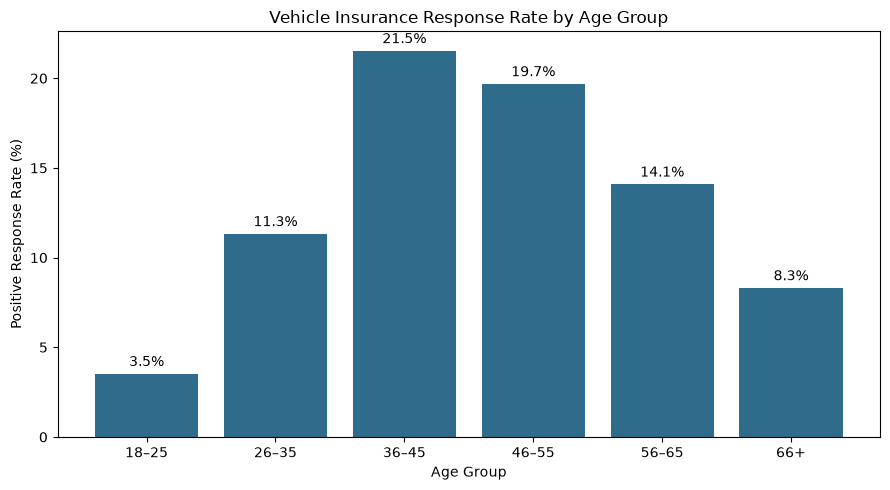

In [27]:
# Plot response rate by age group

plt.figure(figsize=(9, 5))

bars = plt.bar(
    age_analysis.index.astype(str),
    age_analysis["Response_Rate"],
    color="#2F6B8A"
)

plt.title("Vehicle Insurance Response Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in age_analysis["Response_Rate"]],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Customer Response by Age

Customers aged 36–45 recorded the highest positive response rate (21.54%), followed by customers aged 46–55 (19.70%). The lowest response rate was observed among customers aged 18–25 (3.53%).

Response rates increase from younger to middle-aged customers and decline among older age groups.

**Business implication:** Middle-aged customer segments may warrant further investigation for vehicle insurance campaigns. Age alone should not determine targeting; other customer characteristics and campaign performance should also be evaluated.


Analyze previous vehicle insurance

In [28]:
# Check the values in Previously_Insured
df["Previously_Insured"].value_counts().sort_index()

Previously_Insured
0    206481
1    174628
Name: count, dtype: int64

0 = customer was not previously insured
1 = customer was previously insured

Response rate by previous insurance

In [29]:
# Analyze response based on previous vehicle insurance

previous_insurance_analysis = df.groupby("Previously_Insured").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

previous_insurance_analysis["Response_Rate"] *= 100

display(previous_insurance_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Previously_Insured,,,
0,206481,46552,22.55
1,174628,158,0.09


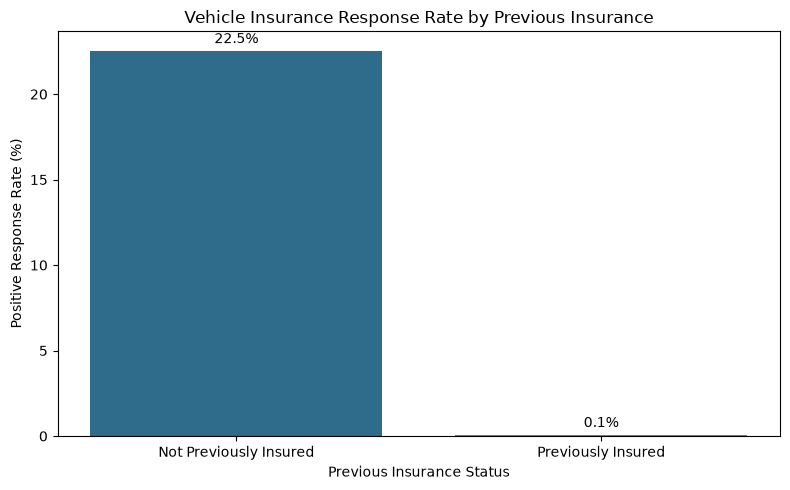

In [30]:
# Visualize response rate by previous insurance

labels = ["Not Previously Insured", "Previously Insured"]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    previous_insurance_analysis["Response_Rate"],
    color=["#2F6B8A", "#7A7A7A"]
)

plt.title("Vehicle Insurance Response Rate by Previous Insurance")
plt.xlabel("Previous Insurance Status")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in previous_insurance_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Previous Vehicle Insurance

Customers without previous vehicle insurance recorded a positive response rate of 22.55%, compared with only 0.09% among customers who already had vehicle insurance.

This is one of the strongest differences observed so far in the customer segmentation analysis.

**Business implication:** Customers without existing vehicle insurance may represent a promising segment for cross-selling. However, this finding should be validated alongside other characteristics and campaign constraints.


Analyze vehicle damage history

Are customers with vehicle damage history more likely to respond positively?

In [31]:
# Check vehicle damage categories
df["Vehicle_Damage"].value_counts()

Vehicle_Damage
Yes    192413
No     188696
Name: count, dtype: int64

Response rate by vehicle damage

In [32]:
# Analyze response based on vehicle damage history

damage_analysis = df.groupby("Vehicle_Damage").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

damage_analysis["Response_Rate"] *= 100

display(damage_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Vehicle_Damage,,,
No,188696,982,0.52
Yes,192413,45728,23.77


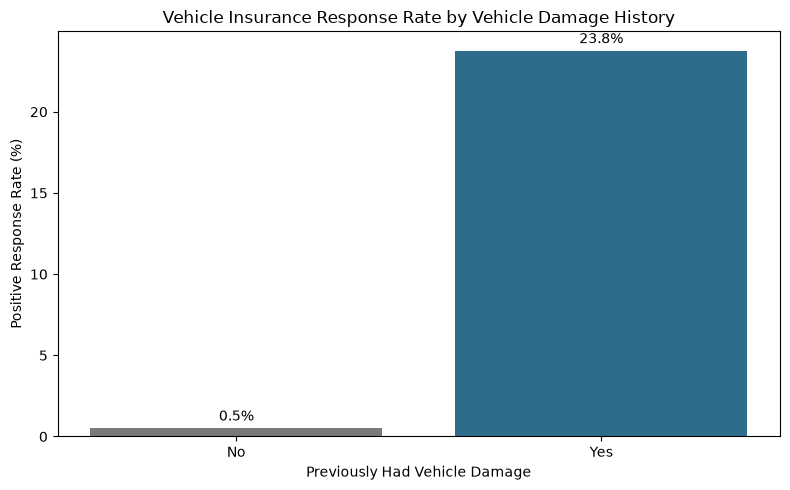

In [33]:
# Plot response rate by vehicle damage history

damage_analysis = damage_analysis.reindex(["No", "Yes"])

plt.figure(figsize=(8, 5))

bars = plt.bar(
    damage_analysis.index,
    damage_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Vehicle Insurance Response Rate by Vehicle Damage History")
plt.xlabel("Previously Had Vehicle Damage")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in damage_analysis["Response_Rate"]],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Vehicle Damage History

Customers who reported previous vehicle damage had a positive response rate of 23.77%, compared with 0.52% among customers who reported no vehicle damage.

The observed difference is substantial and suggests that vehicle damage history is strongly associated with customer response in this dataset.

**Business implication:** Customers with vehicle damage history may be a promising segment for further cross-sell analysis. This relationship should be considered alongside previous insurance status and other customer characteristics.


Analyze vehicle age

Does the age of a customer's vehicle relate to their response to the insurance offer?

In [34]:
# Check vehicle age categories and customer counts

df["Vehicle_Age"].value_counts()

Vehicle_Age
1-2 Year     200316
< 1 Year     164786
> 2 Years     16007
Name: count, dtype: int64

Calculate response rate by vehicle age

In [35]:
# Analyze response based on vehicle age

vehicle_age_analysis = df.groupby("Vehicle_Age").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

vehicle_age_analysis["Response_Rate"] *= 100

# Arrange categories in a logical order
vehicle_age_analysis = vehicle_age_analysis.reindex(
    ["< 1 Year", "1-2 Year", "> 2 Years"]
)

display(vehicle_age_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Vehicle_Age,,,
< 1 Year,164786,7202,4.37
1-2 Year,200316,34806,17.38
> 2 Years,16007,4702,29.37


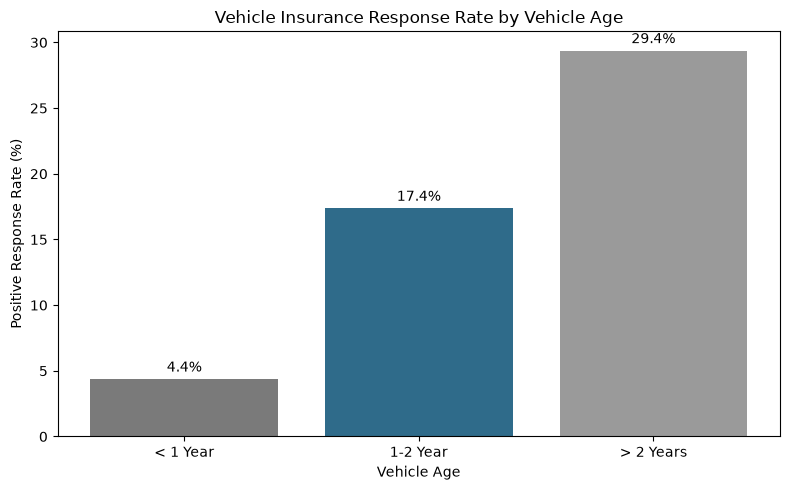

In [36]:
# Plot response rate by vehicle age

plt.figure(figsize=(8, 5))

bars = plt.bar(
    vehicle_age_analysis.index,
    vehicle_age_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A", "#9A9A9A"]
)

plt.title("Vehicle Insurance Response Rate by Vehicle Age")
plt.xlabel("Vehicle Age")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in vehicle_age_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Vehicle Age

Customers with vehicles older than 2 years recorded the highest positive response rate (29.37%), followed by customers with vehicles aged 1–2 years (17.38%). Customers with vehicles less than 1 year old had the lowest response rate (4.37%).

**Business implication:** Vehicle age may be a useful factor for customer segmentation. Customers with older vehicles could be investigated further as a potential cross-sell segment. However, the group with vehicles older than 2 years is comparatively small, and this association does not establish causality.


Analyze annual premium

In [37]:
# Summarize annual premium by response

premium_analysis = df.groupby("Response")["Annual_Premium"].agg(
    ["count", "mean", "median", "min", "max"]
)

premium_analysis.index = [
    "No Positive Response",
    "Positive Response"
]

display(premium_analysis.round(2))

,count,mean,median,min,max
No Positive Response,334399,30419.16,31504.0,2630.0,540165.0
Positive Response,46710,31604.09,33002.0,2630.0,540165.0


Customers who responded positively had a higher mean annual premium: 31,604.09 versus 30,419.16.



Their median premium was also higher: 33,002 versus 31,504.



Both groups have the same reported minimum and maximum.

Visualize annual premium distribution

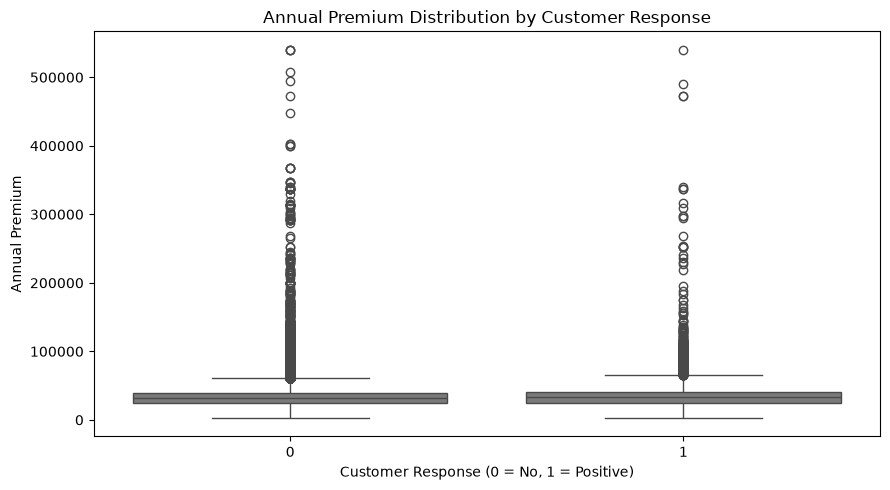

In [38]:
# Compare annual premium distributions by customer response

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Response",
    y="Annual_Premium",
    color="#7A7A7A"
)

plt.title("Annual Premium Distribution by Customer Response")
plt.xlabel("Customer Response (0 = No, 1 = Positive)")
plt.ylabel("Annual Premium")

plt.tight_layout()
plt.show()


### Key Insight — Annual Premium

Customers who responded positively had a slightly higher mean annual premium (31,604.09) and median premium (33,002) than customers who did not respond positively (mean: 30,419.16; median: 31,504).

The distributions appear broadly similar, with substantial high-value outliers in both groups.

**Business implication:** Annual premium may provide some useful information, but its relationship with customer response appears less pronounced than the differences observed for previous insurance, vehicle damage history, and vehicle age. Further analysis is required.


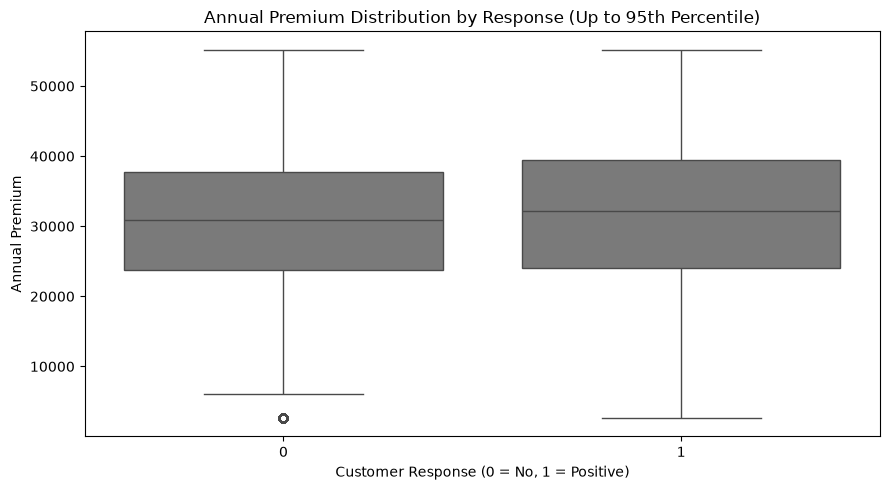

In [39]:
# Calculate the 95th percentile for visualization
premium_95th = df["Annual_Premium"].quantile(0.95)

# Plot the premium distribution below the 95th percentile
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df[df["Annual_Premium"] <= premium_95th],
    x="Response",
    y="Annual_Premium",
    color="#7A7A7A"
)

plt.title("Annual Premium Distribution by Response (Up to 95th Percentile)")
plt.xlabel("Customer Response (0 = No, 1 = Positive)")
plt.ylabel("Annual Premium")

plt.tight_layout()
plt.show()


### Visualization Note

To improve readability, this boxplot displays annual premiums up to the 95th percentile. The remaining 5% of observations are excluded from this visualization only and remain in the original dataset.

The two response groups show considerable overlap in annual premium distributions, suggesting that annual premium alone may not strongly distinguish positive responders from non-responders.


Sales channel analysis

In [40]:
# Check the number of unique sales channels
df["Policy_Sales_Channel"].nunique()

155

In [41]:
# Display the most common sales channels
df["Policy_Sales_Channel"].value_counts().head(10)

Policy_Sales_Channel
152.0    134784
26.0      79700
124.0     73995
160.0     21779
156.0     10661
122.0      9930
157.0      6684
154.0      5993
151.0      3885
163.0      2893
Name: count, dtype: int64

response rates by sales channel

In [42]:
# Calculate customer count and response rate for each sales channel

channel_analysis = df.groupby("Policy_Sales_Channel").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

channel_analysis["Response_Rate"] *= 100

# Select the 10 most common channels by customer volume
top_10_channels = channel_analysis.nlargest(10, "Customer_Count")

display(top_10_channels.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Policy_Sales_Channel,,,
152.0,134784,3858,2.86
26.0,79700,15891,19.94
124.0,73995,13996,18.91
160.0,21779,475,2.18
156.0,10661,2297,21.55
122.0,9930,1720,17.32
157.0,6684,1794,26.84
154.0,5993,1474,24.60
151.0,3885,122,3.14


Visualize response rates for the top 10 channels

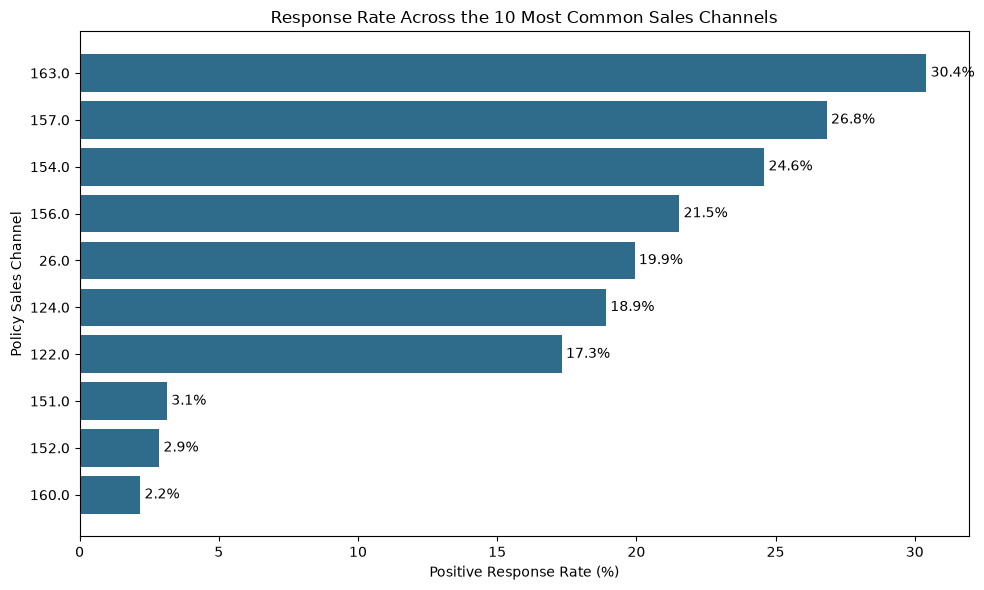

In [43]:
# Sort selected channels by response rate for easier comparison

top_10_response = top_10_channels.sort_values("Response_Rate")

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10_response.index.astype(str),
    top_10_response["Response_Rate"],
    color="#2F6B8A"
)

plt.title("Response Rate Across the 10 Most Common Sales Channels")
plt.xlabel("Positive Response Rate (%)")
plt.ylabel("Policy Sales Channel")

plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in top_10_response["Response_Rate"]],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Policy Sales Channel

Response rates varied substantially across the 10 most common policy sales channels. Channel 163 recorded the highest response rate (30.42%), while channel 160 recorded the lowest (2.18%).

Channel 152 had the largest customer volume (134,784) but a relatively low response rate of 2.86%. In contrast, channel 26 reached 79,700 customers and achieved a 19.94% response rate.

**Business implication:** Sales channel may be an important factor in understanding customer response. Channel performance should be evaluated using both customer volume and response rate. Channel IDs are categorical identifiers, and their underlying meaning is not available in this dataset.


Analyze response by gender

In [44]:
df["Gender"].value_counts()

Gender
Male      206089
Female    175020
Name: count, dtype: int64

Response rate by gender

In [45]:
# Calculate response rate by gender

gender_analysis = df.groupby("Gender").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

gender_analysis["Response_Rate"] *= 100

display(gender_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Gender,,,
Female,175020,18185,10.39
Male,206089,28525,13.84


Male customers had a positive response rate of 13.84%.

Female customers had a positive response rate of 10.39%.

The observed difference is 3.45 percentage points.

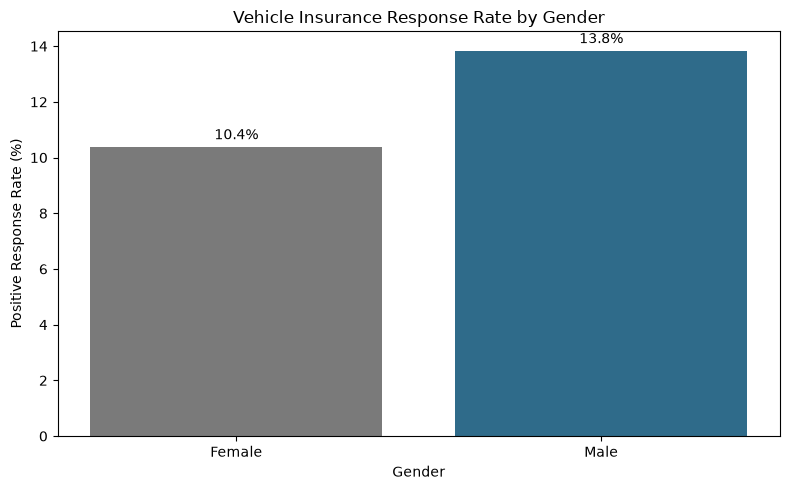

In [46]:
# Plot response rate by gender

gender_analysis = gender_analysis.reindex(["Female", "Male"])

plt.figure(figsize=(8, 5))

bars = plt.bar(
    gender_analysis.index,
    gender_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Vehicle Insurance Response Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in gender_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Customer Response by Gender

Male customers recorded a positive response rate of 13.84%, compared with 10.39% among female customers. The observed difference was 3.45 percentage points.

**Business implication:** Gender shows a response-rate difference in this dataset, but it should be evaluated alongside other customer characteristics. This descriptive result does not establish causality or justify gender-based targeting on its own.


Analyze response by region

In [47]:
# Check the number of unique regions
df["Region_Code"].nunique()

53

In [48]:
# Display the 10 regions with the most customers
df["Region_Code"].value_counts().head(10)

Region_Code
28.0    106415
8.0      33877
46.0     19749
41.0     18263
15.0     13308
30.0     12191
29.0     11065
50.0     10243
3.0       9251
11.0      9232
Name: count, dtype: int64

Response rate by region

In [49]:
# Calculate customer count and response rate by region

region_analysis = df.groupby("Region_Code").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

region_analysis["Response_Rate"] *= 100

# Select the 10 regions with the highest customer volume
top_10_regions = region_analysis.nlargest(10, "Customer_Count")

display(top_10_regions.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Region_Code,,,
28.0,106415,19917,18.72
8.0,33877,3257,9.61
46.0,19749,2032,10.29
41.0,18263,2224,12.18
15.0,13308,958,7.20
30.0,12191,900,7.38
29.0,11065,1365,12.34
50.0,10243,642,6.27
3.0,9251,1181,12.77


Region 28 has the highest response rate among the 10 most common regions: 18.72%.

Region 28 also has the largest customer count.

Region 50 has the lowest response rate in this group: 6.27%.

Response rates vary substantially across these regions.

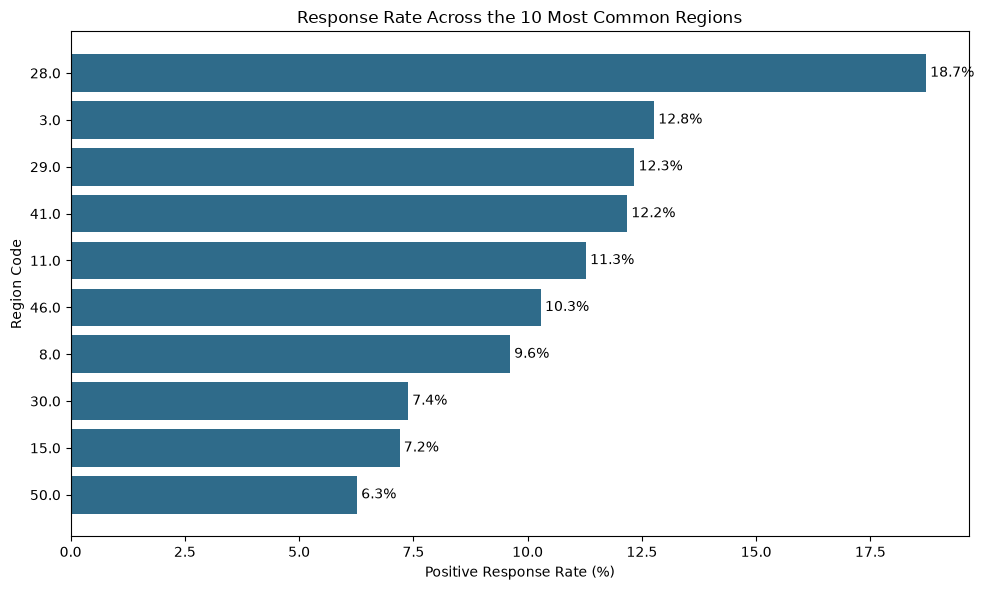

In [50]:
# Sort regions by response rate

top_10_region_rates = top_10_regions.sort_values("Response_Rate")

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10_region_rates.index.astype(str),
    top_10_region_rates["Response_Rate"],
    color="#2F6B8A"
)

plt.title("Response Rate Across the 10 Most Common Regions")
plt.xlabel("Positive Response Rate (%)")
plt.ylabel("Region Code")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in top_10_region_rates["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()


### Key Insight — Regional Response

Response rates varied across the 10 most common regions. Region 28 recorded the highest response rate (18.72%) and the largest customer volume (106,415), while Region 50 recorded the lowest response rate (6.27%).

**Business implication:** Region codes may help identify differences in customer response. Further investigation is needed before drawing geographic conclusions, because the dataset does not provide descriptive names for the regions.


Analyze driving license status

In [51]:
df["Driving_License"].value_counts().sort_index()

Driving_License
0       812
1    380297
Name: count, dtype: int64

response rates by driving-license status

In [52]:
# Calculate response rate by driving-license status

license_analysis = df.groupby("Driving_License").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

license_analysis["Response_Rate"] *= 100

display(license_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Driving_License,,,
0,812,41,5.05
1,380297,46669,12.27


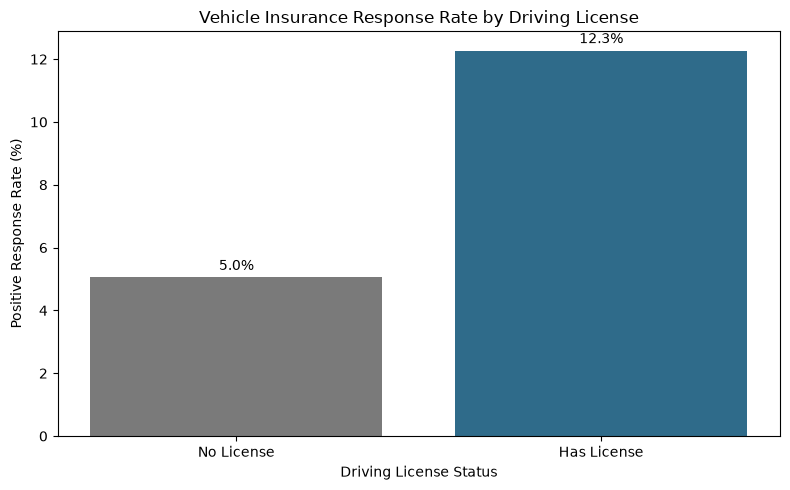

In [53]:
# Plot response rate by driving-license status

license_analysis = license_analysis.reindex([0, 1])

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["No License", "Has License"],
    license_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Vehicle Insurance Response Rate by Driving License")
plt.xlabel("Driving License Status")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in license_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()

### Key Insight — Driving License

Customers with a driving license recorded a positive response rate of 12.27%, compared with 5.05% among customers without a license.

However, only 812 customers (0.21% of the dataset) did not have a driving license. The imbalance in group sizes should be considered when interpreting this comparison.

**Business implication:** Driving-license status may provide some information about response, but its limited variation in this dataset may reduce its usefulness for customer segmentation.


Analyze customer vintage
Vintage represents how long the customer has been associated with the company, measured in days in this dataset.

In [54]:
# Summary statistics for customer vintage

df["Vintage"].describe().round(2)

count    381109.00
mean        154.35
std          83.67
min          10.00
25%          82.00
50%         154.00
75%         227.00
max         299.00
Name: Vintage, dtype: float64

In [55]:
# Compare customer vintage by response

vintage_analysis = df.groupby("Response")["Vintage"].agg(
    ["count", "mean", "median", "min", "max"]
)

vintage_analysis.index = [
    "No Positive Response",
    "Positive Response"
]

display(vintage_analysis.round(2))

,count,mean,median,min,max
No Positive Response,334399,154.38,154.0,10,299
Positive Response,46710,154.11,154.0,10,299



### Key Insight — Customer Vintage

The mean customer vintage was 154.38 days among customers who did not respond positively and 154.11 days among positive responders. Both groups had a median vintage of 154 days.

The distributions appear similar based on these summary statistics.

**Business implication:** Customer vintage alone may have limited descriptive value for distinguishing positive responders from non-responders. Its usefulness should be evaluated alongside other features.



# 4. Exploratory Data Analysis — Summary

## Overview
The dataset contains 381,109 customer records and 12 columns. No missing values or exact duplicate rows were identified during the initial data-quality audit.

The overall positive response rate to the vehicle insurance offer was 12.26%.

## Key Findings
- Customers aged 36–45 recorded the highest response rate among the age groups analyzed (21.54%).
- Customers without previous vehicle insurance had a response rate of 22.55%.
- Customers with vehicle damage history had a response rate of 23.77%.
- Customers with vehicles older than 2 years had a response rate of 29.37%.
- Response rates varied substantially across sales channels and regions.
- Male customers had a response rate of 13.84%, compared with 10.39% for female customers.
- Annual premium distributions overlapped considerably between response groups.
- Customer vintage statistics were similar for positive responders and non-responders.

## Limitations
- The analysis is observational and does not establish causality.
- The dataset contains an imbalanced target variable.
- Sales channel and region codes lack descriptive labels.
- Segment-level response rates do not guarantee future campaign performance.

## Next Steps
Further data validation, feature analysis, and statistical investigation will be performed before predictive modeling.


2 — Data Cleaning & Validation


Create a working dataset
# 5. Data Cleaning and Validation

In this section, a separate working copy of the original dataset will be created.

The original dataset will remain unchanged to preserve data integrity and allow reproducibility.


In [62]:
# Keep the original dataset unchanged
df_raw = pd.read_csv("../data/train.csv")

# Create a separate working copy
df_clean = df_raw.copy()

print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_clean.shape)
print("Columns:", df_clean.columns.tolist())

Original dataset shape: (381109, 12)
Working dataset shape: (381109, 12)
Columns: ['id', 'Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']


In [63]:
# Check dataset structure and data types
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  str    
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  str    
 7   Vehicle_Damage        381109 non-null  str    
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 40.5 MB


In [64]:
# Check missing values in each column
print("Missing values:")
print(df_clean.isnull().sum())

# Check exact duplicate rows
print("\nDuplicate rows:", df_clean.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate IDs:", df_clean["id"].duplicated().sum())

Missing values:
id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

Duplicate rows: 0
Duplicate IDs: 0


Validate categorical values

In [65]:
# Check unique values in categorical columns

categorical_columns = [
    "Gender",
    "Driving_License",
    "Previously_Insured",
    "Vehicle_Age",
    "Vehicle_Damage",
    "Response"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts())


Gender:
Gender
Male      206089
Female    175020
Name: count, dtype: int64

Driving_License:
Driving_License
1    380297
0       812
Name: count, dtype: int64

Previously_Insured:
Previously_Insured
0    206481
1    174628
Name: count, dtype: int64

Vehicle_Age:
Vehicle_Age
1-2 Year     200316
< 1 Year     164786
> 2 Years     16007
Name: count, dtype: int64

Vehicle_Damage:
Vehicle_Damage
Yes    192413
No     188696
Name: count, dtype: int64

Response:
Response
0    334399
1     46710
Name: count, dtype: int64


Check numerical ranges and target values

In [66]:
# Check numerical columns for unexpected ranges

numerical_columns = [
    "Age",
    "Region_Code",
    "Annual_Premium",
    "Policy_Sales_Channel",
    "Vintage"
]

df_clean[numerical_columns].describe()

,Age,Region_Code,Annual_Premium,Policy_Sales_Channel,Vintage
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,38.822584,26.388807,30564.389581,112.034295,154.347397
std,15.511611,13.229888,17213.155057,54.203995,83.671304
min,20.000000,0.000000,2630.000000,1.000000,10.000000
25%,25.000000,15.000000,24405.000000,29.000000,82.000000
50%,36.000000,28.000000,31669.000000,133.000000,154.000000
75%,49.000000,35.000000,39400.000000,152.000000,227.000000
max,85.000000,52.000000,540165.000000,163.000000,299.000000


Age: 20–85 years — plausible range for this dataset.

Region_Code: 0–52 — numeric codes, categorical in meaning.

Annual_Premium: ₹2,630–₹540,165 — maximum is much higher than the 75th percentile (₹39,400), so there are extreme values to investigate.

Policy_Sales_Channel: 1–163 — category codes, not continuous measurements.

Vintage: 10–299 — customer tenure values; no negative values.

In [67]:
# Calculate IQR-based outlier boundaries for Annual_Premium

Q1 = df_clean["Annual_Premium"].quantile(0.25)
Q3 = df_clean["Annual_Premium"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["Annual_Premium"] < lower_bound) |
    (df_clean["Annual_Premium"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df_clean) * 100, 2), "%")

Q1: 24405.0
Q3: 39400.0
IQR: 14995.0
Lower bound: 1912.5
Upper bound: 61892.5
Number of outliers: 10320
Outlier percentage: 2.71 %


10,320 records have annual premiums above the IQR upper boundary of 61,892.50. There are no lower-bound outliers because the minimum premium is 2,630.

These are statistical outliers, not necessarily data errors. Since the dataset has no missing values or duplicates and the premiums are positive, we should preserve the original records for now.

Check binary variables and ID integrity

In [68]:
# Validate binary columns
binary_columns = [
    "Driving_License",
    "Previously_Insured",
    "Response"
]

for column in binary_columns:
    print(f"{column}: {sorted(df_clean[column].unique())}")

# Check ID range
print("\nID minimum:", df_clean["id"].min())
print("ID maximum:", df_clean["id"].max())
print("Unique IDs:", df_clean["id"].nunique())

Driving_License: [np.int64(0), np.int64(1)]
Previously_Insured: [np.int64(0), np.int64(1)]
Response: [np.int64(0), np.int64(1)]

ID minimum: 1
ID maximum: 381109
Unique IDs: 381109


Validate all categorical labels

In [69]:
# Validate categorical labels
categorical_columns = [
    "Gender",
    "Vehicle_Age",
    "Vehicle_Damage"
]

for column in categorical_columns:
    print(f"\n{column} unique values:")
    print(df_clean[column].unique())


Gender unique values:
<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

Vehicle_Age unique values:
<ArrowStringArray>
['> 2 Years', '1-2 Year', '< 1 Year']
Length: 3, dtype: str

Vehicle_Damage unique values:
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


## Phase 2: Data Cleaning and Validation

### Objective
Validate the original dataset's structure, completeness, uniqueness, categorical values, numerical ranges, and potential outliers before proceeding to feature engineering or modeling.

### Validation Results
- Dataset contains **381,109 rows and 12 columns**.
- No missing values were detected.
- No duplicate rows were detected.
- No duplicate customer IDs were detected.
- Customer IDs range from 1 to 381,109, with all IDs unique.
- Binary columns (`Driving_License`, `Previously_Insured`, and `Response`) contain only 0 and 1.
- Categorical columns (`Gender`, `Vehicle_Age`, and `Vehicle_Damage`) contain expected categories.
- Numerical ranges were reviewed using descriptive statistics.
- The IQR method identified **10,320 Annual_Premium observations (2.71%)** above the upper boundary of 61,892.50.

### Cleaning Decisions
No rows were removed or values imputed because the dataset contained no missing values or duplicates.

Potential Annual_Premium outliers were retained because statistical outliers are not necessarily invalid records. They will be considered during further analysis and modeling.

### Conclusion
The dataset passed the initial structural and data-quality checks. It is suitable for continued exploratory analysis and preparation, subject to appropriate feature validation and preprocessing in later stages.

Review feature meanings

In [70]:
# Review dataset columns and data types

for column in df_clean.columns:
    print(f"{column}: {df_clean[column].dtype}")

id: int64
Gender: str
Age: int64
Driving_License: int64
Region_Code: float64
Previously_Insured: int64
Vehicle_Age: str
Vehicle_Damage: str
Annual_Premium: float64
Policy_Sales_Channel: float64
Vintage: int64
Response: int64


Create an age-group feature

In [71]:
# Create age groups for customer segmentation

age_bins = [18, 25, 35, 45, 55, 65, 100]

age_labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

df_clean[["Age", "Age_Group"]].head(10)

,Age,Age_Group
0,44,36-45
1,76,66+
2,47,46-55
3,21,18-25
4,29,26-35
5,24,18-25
6,23,18-25
7,56,56-65
8,24,18-25
9,32,26-35


Validate the new feature

In [72]:
# Check age-group counts and missing values

print(df_clean["Age_Group"].value_counts().sort_index())

print("\nMissing Age_Group values:",
      df_clean["Age_Group"].isnull().sum())

Age_Group
18-25    114505
26-35     72307
36-45     70532
46-55     61549
56-65     34147
66+       28069
Name: count, dtype: int64

Missing Age_Group values: 0


Create a business-focused feature

In [73]:
# Create premium categories based on quartiles

df_clean["Premium_Category"] = pd.qcut(
    df_clean["Annual_Premium"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

df_clean["Premium_Category"].value_counts().sort_index()

Premium_Category
Low          95283
Medium       95286
High         95263
Very High    95277
Name: count, dtype: int64

Validate the engineered features together

In [74]:
# Check the engineered features

print("Age_Group missing:", df_clean["Age_Group"].isnull().sum())
print("Premium_Category missing:", df_clean["Premium_Category"].isnull().sum())

print("\nUpdated dataset shape:", df_clean.shape)

df_clean[["Age", "Age_Group", "Annual_Premium", "Premium_Category"]].head()

Age_Group missing: 0
Premium_Category missing: 0

Updated dataset shape: (381109, 14)


,Age,Age_Group,Annual_Premium,Premium_Category
0,44,36-45,40454.0,Very High
1,76,66+,33536.0,High
2,47,46-55,38294.0,High
3,21,18-25,28619.0,Medium
4,29,26-35,27496.0,Medium


## Phase 3: Feature Engineering

### Objective
Create business-oriented features to support customer segmentation and exploratory analysis.

### Features Created

**1. Age_Group**
- Segmented customers into six age groups: 18–25, 26–35, 36–45, 46–55, 56–65, and 66+.
- Retained the original `Age` feature.
- All 381,109 records were assigned to a group, with no missing values.

**2. Premium_Category**
- Segmented `Annual_Premium` into four quartile-based groups: Low, Medium, High, and Very High.
- Categories contain approximately equal numbers of customers.
- No missing values were introduced.

### Limitations and Considerations
- Age groups simplify continuous age information and may hide variation within each segment.
- Premium categories are relative to this dataset and should not be interpreted as fixed market price bands.
- For predictive modeling, premium-category boundaries must be calculated using training data only to prevent data leakage.
- Engineered categorical features will be evaluated for usefulness before modeling.

### Conclusion
Two additional features were created and validated. The original numerical variables were preserved for further analysis and potential modeling.

Phase 4: Business Questions & Analytical Insights

## Phase 4: Business Questions and Analytical Insights

### Business Objective
Identify customer segments with higher likelihood of responding to a vehicle insurance cross-selling offer. The analysis aims to support more focused marketing campaigns and improve customer targeting.

### Key Business Questions
1. Which age groups show higher response rates?
2. How does previous insurance status relate to customer response?
3. Are customers reporting vehicle damage more likely to respond?
4. Does vehicle age influence observed response patterns?
5. Which policy sales channels have higher response rates?
6. How does annual premium differ between responders and non-responders?
7. Which customer characteristics are most associated with response?

### Analytical Approach
- Compare response rates across customer segments.
- Examine both customer counts and response percentages.
- Consider sample sizes when interpreting segment results.
- Distinguish descriptive associations from causal conclusions.
- Avoid treating observed patterns as proof that a feature causes customer response.

### Business Context
The findings may help identify promising customer segments for future campaign testing. Recommendations will be based on observed patterns and should be validated through controlled marketing experiments before implementation.

Response rate by customer segment

In [76]:
def response_summary(data, group_column):
    summary = (
        data.groupby(group_column, observed=True)["Response"]
        .agg(
            Customers="count",
            Responders="sum",
            Response_Rate="mean"
        )
        .reset_index()
    )

    summary["Response_Rate"] = (
        summary["Response_Rate"] * 100
    ).round(2)

    return summary.sort_values(
        "Response_Rate",
        ascending=False
    )

In [77]:
# Response rate by age group

age_response = response_summary(
    df_clean,
    "Age_Group"
)

age_response

,Age_Group,Customers,Responders,Response_Rate
2,36-45,70532,15192,21.54
3,46-55,61549,12123,19.70
4,56-65,34147,4815,14.10
1,26-35,72307,8198,11.34
5,66+,28069,2335,8.32
0,18-25,114505,4047,3.53


Customers aged 36–45 have the highest response rate at 21.54%, while customers aged 18–25 have the lowest at 3.53%.

The response rate difference is:
\[
21.54\%-3.53\%=18.01 \text{ percentage points}
\]

**Age-Based Customer Response**

Customers aged 36–45 showed the highest response rate (21.54%), followed by customers aged 46–55 (19.70%). The youngest segment, aged 18–25, had the lowest response rate (3.53%). These findings suggest that middle-aged customers may be a promising segment for further cross-selling campaign evaluation. However, campaign targeting should be validated through controlled testing before implementation.

Response rate by previous insurance status

In [78]:
previous_insurance_response = response_summary(
    df_clean,
    "Previously_Insured"
)

previous_insurance_response

,Previously_Insured,Customers,Responders,Response_Rate
0,0,206481,46552,22.55
1,1,174628,158,0.09


Customers who were not previously insured had a response rate of 22.55%, compared with only 0.09% among customers who were previously insured.

This is a very large observed difference:
\[
22.55\%-0.09\%=22.46 \text{ percentage points}
\]

Business interpretation: Customers without previous insurance appear to be a substantially more promising segment for cross-selling vehicle insurance.

However, this is an observed association in the dataset—not proof that previous insurance status causes response.

**Previous Insurance Status and Customer Response**

Customers who were not previously insured showed a response rate of 22.55%, compared with 0.09% among previously insured customers. This substantial difference suggests that customers without existing insurance may represent a promising segment for cross-selling campaigns. Marketing teams could investigate this segment further, while validating campaign effectiveness through controlled experiments.

Response rate by vehicle damage

In [79]:
vehicle_damage_response = response_summary(
    df_clean,
    "Vehicle_Damage"
)

vehicle_damage_response

,Vehicle_Damage,Customers,Responders,Response_Rate
1,Yes,192413,45728,23.77
0,No,188696,982,0.52


**Vehicle Damage and Customer Response**

Customers with vehicle damage history showed a response rate of 23.77%, compared with 0.52% among customers without reported damage. This substantial difference indicates that vehicle damage history is strongly associated with response to the cross-selling offer. The segment may warrant further evaluation for campaign targeting, subject to validation and appropriate business considerations.

Customers with vehicle damage reported had a response rate of 23.77%, compared with just 0.52% for customers without reported vehicle damage.

Difference:
\[
23.77\%-0.52\%=23.25\text{ percentage points}
\]

Business interpretation: Vehicle damage history is strongly associated with customer response in this dataset. Customers reporting vehicle damage may be a promising segment for further campaign evaluation.

Response rate by vehicle age

In [80]:
vehicle_age_response = response_summary(
    df_clean,
    "Vehicle_Age"
)

vehicle_age_response

,Vehicle_Age,Customers,Responders,Response_Rate
2,> 2 Years,16007,4702,29.37
0,1-2 Year,200316,34806,17.38
1,< 1 Year,164786,7202,4.37


Customers with vehicles older than 2 years had the highest response rate (29.37%), while customers with vehicles younger than 1 year had the lowest (4.37%).

Difference:
\[
29.37\%-4.37\%=25.00\text{ percentage points}
\]

Business interpretation: Customers with older vehicles appear more likely to respond to the cross-selling offer. However, the > 2 Years segment is comparatively small, with 16,007 customers, so we should consider its size when making recommendations.

**Vehicle Age and Customer Response**

Customers with vehicles older than two years demonstrated the highest response rate (29.37%), compared with 17.38% for vehicles aged 1–2 years and 4.37% for vehicles younger than one year. This pattern suggests that vehicle age is associated with customer response. The older-vehicle segment may be worth investigating for targeted campaigns, while considering its smaller customer base.

Response rate by policy sales channel

In [81]:
# Find the 10 most frequent policy sales channels
top_channels = df_clean["Policy_Sales_Channel"].value_counts().head(10).index

channel_data = df_clean[
    df_clean["Policy_Sales_Channel"].isin(top_channels)
]

channel_response = response_summary(
    channel_data,
    "Policy_Sales_Channel"
)

channel_response

,Policy_Sales_Channel,Customers,Responders,Response_Rate
9,163.0,2893,880,30.42
7,157.0,6684,1794,26.84
5,154.0,5993,1474,24.60
6,156.0,10661,2297,21.55
0,26.0,79700,15891,19.94
2,124.0,73995,13996,18.91
1,122.0,9930,1720,17.32
3,151.0,3885,122,3.14
4,152.0,134784,3858,2.86
8,160.0,21779,475,2.18


**Policy Sales Channel Performance**

Response rates varied substantially across the ten most frequent policy sales channels. Channel 163 recorded the highest response rate (30.42%), while Channel 160 had the lowest (2.18%) among these channels. Channel 26 generated the largest number of responders (15,891), despite having a lower response rate than several smaller channels. This highlights the importance of evaluating both response rate and customer volume when assessing channel performance.

These findings are descriptive. Channel codes are identifiers, and their operational meaning cannot be inferred without channel documentation.

Annual Premium vs. Response

In [82]:
premium_response_summary = (
    df_clean.groupby("Response")["Annual_Premium"]
    .agg(
        Customers="count",
        Mean_Premium="mean",
        Median_Premium="median"
    )
    .round(2)
)

premium_response_summary

,Customers,Mean_Premium,Median_Premium
Response,,,
0,334399,30419.16,31504.0
1,46710,31604.09,33002.0


**Annual Premium and Customer Response**

Responders had a higher average annual premium (31,604.09) than non-responders (30,419.16). The median premium was also higher among responders (33,002 compared with 31,504). However, the difference was modest relative to the overall premium variation. Annual premium may provide some descriptive insight into response behavior, but it should not be treated as a strong standalone targeting factor without further analysis.

consolidated business insights table

In [83]:
business_insights = pd.DataFrame({
    "Business_Factor": [
        "Age Group",
        "Previously Insured",
        "Vehicle Damage",
        "Vehicle Age",
        "Policy Sales Channel",
        "Annual Premium"
    ],
    "Key_Finding": [
        "Age 36-45 had the highest response rate (21.54%).",
        "Customers not previously insured had a 22.55% response rate.",
        "Customers reporting vehicle damage had a 23.77% response rate.",
        "Vehicles older than 2 years had a 29.37% response rate.",
        "Channel 163 had the highest response rate among the top 10 channels (30.42%).",
        "Responders had a higher median premium (33,002 vs. 31,504)."
    ],
    "Business_Implication": [
        "Evaluate middle-aged customers for campaign targeting.",
        "Investigate customers without previous insurance.",
        "Evaluate vehicle-damage history as a segmentation variable.",
        "Explore older-vehicle owners as a potential segment.",
        "Investigate high-performing channels while considering volume.",
        "Assess premium alongside other customer characteristics."
    ]
})

business_insights

,Business_Factor,Key_Finding,Business_Implication
0,Age Group,Age 36-45 had the highest response rate (21.54%).,Evaluate middle-aged customers for campaign ta...
1,Previously Insured,Customers not previously insured had a 22.55% ...,Investigate customers without previous insurance.
2,Vehicle Damage,Customers reporting vehicle damage had a 23.77...,Evaluate vehicle-damage history as a segmentat...
3,Vehicle Age,Vehicles older than 2 years had a 29.37% respo...,Explore older-vehicle owners as a potential se...
4,Policy Sales Channel,Channel 163 had the highest response rate amon...,Investigate high-performing channels while con...
5,Annual Premium,"Responders had a higher median premium (33,002...",Assess premium alongside other customer charac...


Business Analysis Conclusion

## Phase 4: Business Analysis and Key Insights

### Summary of Findings

The exploratory analysis identified several customer characteristics associated with response to the vehicle insurance cross-selling offer:

- Customers aged 36–45 had the highest response rate among age groups (21.54%).
- Customers without previous insurance had a response rate of 22.55%, compared with 0.09% among previously insured customers.
- Customers reporting vehicle damage had a response rate of 23.77%, compared with 0.52% among customers without reported damage.
- Customers with vehicles older than two years had the highest response rate by vehicle age (29.37%).
- Policy sales channel response rates varied considerably. Channel 163 had the highest response rate among the ten most frequent channels (30.42%).
- Responders had a higher median annual premium than non-responders (33,002 compared with 31,504).

### Business Recommendations

1. Investigate customers without previous insurance as a potential cross-selling segment.
2. Evaluate vehicle damage history and vehicle age as useful customer segmentation variables.
3. Consider both response rate and customer volume when comparing sales channels.
4. Use age-group analysis to support campaign segmentation, while avoiding assumptions about individual customers.
5. Validate potential targeting strategies through controlled marketing experiments.

### Limitations

These findings describe associations within the dataset and do not establish causation. Channel codes do not reveal the underlying channel names. Response patterns should be validated on new data before operational use.

### Conclusion

The analysis identified meaningful differences in customer response across insurance status, vehicle damage history, vehicle age, age group, and policy sales channel. These insights provide a foundation for further statistical analysis and predictive modeling.

Phase 5: Statistical Analysis & Insight Validation

Phase 5.1 — Chi-square test
First, we’ll test previous insurance status vs. customer response.
What are we testing?
- H₀ (Null hypothesis): Previous insurance status and response are independent.
- H₁ (Alternative hypothesis): Previous insurance status and response are associated.

Create the contingency table

In [85]:
%pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
    --------------------------------------- 0.5/37.4 MB 689.7 kB/s eta 0:00:54
    --------------------------------------- 0.5/37.4 MB 689.7 kB/s eta 0:00:54
    --------------------------------------- 0.8/37.4 MB 663.3 kB/s eta 0:00:56
    --------------------------------------- 0.8/37.4 MB 663.3 kB/s eta 0:00:56
   - -------------------------------------- 1.0/37.4 MB 669.3 kB/s eta 0:00:55
   - -------------------------------------- 1.0/37.4 MB 669.3 kB/s eta 0:00:55
   - -------------------------------------- 1.3/37.4 MB 661.1 kB/s eta 0:00:55
   - -------------------------------------- 1.6/37.4 MB 682.0 kB/s eta 0:00:53
   - -------------------------------------- 1.6/37.4 MB 682.0 kB/s eta 0:00:53
   - ----


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [86]:
from scipy.stats import chi2_contingency

In [87]:
contingency = pd.crosstab(
    df_clean["Previously_Insured"],
    df_clean["Response"]
)

contingency

Response,0,1
Previously_Insured,,
0,159929,46552
1,174470,158


Run the statistical test

In [88]:
chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 44357.96472219977
P-value: 0.0
Degrees of freedom: 1


Calculate effect size (Cramér’s V)

In [89]:
import numpy as np

n = contingency.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(contingency.shape[0] - 1,
                    contingency.shape[1] - 1))
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.34116243318192124


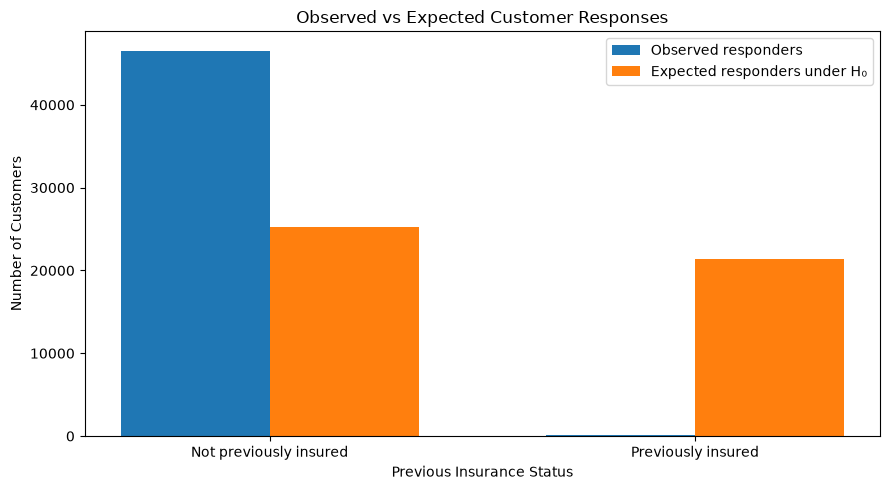

In [90]:
observed = contingency.to_numpy()
expected = chi2_contingency(contingency)[3]

labels = [
    "Not previously insured",
    "Previously insured"
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    observed[:, 1],
    width,
    label="Observed responders"
)

ax.bar(
    x + width / 2,
    expected[:, 1],
    width,
    label="Expected responders under H₀"
)

ax.set_title("Observed vs Expected Customer Responses")
ax.set_xlabel("Previous Insurance Status")
ax.set_ylabel("Number of Customers")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.show()

5.4 — Chi-square test for Vehicle Damage

Create the contingency table

In [91]:
contingency_damage = pd.crosstab(
    df_clean["Vehicle_Damage"],
    df_clean["Response"]
)

contingency_damage

Response,0,1
Vehicle_Damage,,
No,187714,982
Yes,146685,45728


Chi-square test

In [92]:
chi2_damage, p_damage, dof_damage, expected_damage = chi2_contingency(
    contingency_damage
)

print("Chi-square statistic:", chi2_damage)
print("P-value:", p_damage)
print("Degrees of freedom:", dof_damage)

Chi-square statistic: 47864.76180117493
P-value: 0.0
Degrees of freedom: 1


Calculate Cramér’s V

In [93]:
n_damage = contingency_damage.to_numpy().sum()

cramers_v_damage = np.sqrt(
    chi2_damage / (
        n_damage * min(
            contingency_damage.shape[0] - 1,
            contingency_damage.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_damage)

Cramer's V: 0.35439154216182206


### Statistical Validation: Vehicle Damage vs. Customer Response

A chi-square test of independence was conducted to examine the relationship between vehicle damage status and customer response.

- **Chi-square statistic:** 47,864.76
- **Degrees of freedom:** 1
- **P-value:** < 0.05
- **Cramér’s V:** 0.3544

The test indicates a statistically significant association between vehicle damage status and customer response. Cramér’s V suggests a moderate association.

Customers with a vehicle damage history showed a substantially higher response rate in the descriptive analysis. Vehicle damage may therefore be a useful feature for customer segmentation and cross-sell targeting.

**Business implication:** Consider prioritizing customers with vehicle damage history in future targeting experiments, while validating campaign performance through controlled testing.

**Limitation:** This result identifies an association and does not establish causality.

Vehicle Age vs. Response

In [94]:
contingency_vehicle_age = pd.crosstab(
    df_clean["Vehicle_Age"],
    df_clean["Response"]
)

contingency_vehicle_age

Response,0,1
Vehicle_Age,,
1-2 Year,165510,34806
< 1 Year,157584,7202
> 2 Years,11305,4702


Vehicle Age vs. Response

In [95]:
chi2_age, p_age, dof_age, expected_age = chi2_contingency(
    contingency_vehicle_age
)

print("Chi-square statistic:", chi2_age)
print("P-value:", p_age)
print("Degrees of freedom:", dof_age)

Chi-square statistic: 18771.889904151052
P-value: 0.0
Degrees of freedom: 2


Calculate Cramér’s V

In [96]:
n_age = contingency_vehicle_age.to_numpy().sum()

cramers_v_age = np.sqrt(
    chi2_age / (
        n_age * min(
            contingency_vehicle_age.shape[0] - 1,
            contingency_vehicle_age.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_age)

Cramer's V: 0.22193683930699235


### Statistical Validation: Vehicle Age vs. Customer Response

A chi-square test of independence was conducted to evaluate the relationship between vehicle age and customer response.

- **Chi-square statistic:** 18,771.89
- **Degrees of freedom:** 2
- **P-value:** < 0.05
- **Cramér’s V:** 0.2219

The results indicate a statistically significant association between vehicle age and customer response. The effect size suggests a moderate association.

Descriptive analysis showed that customers with vehicles older than two years had the highest response rate, while customers with vehicles younger than one year had the lowest response rate.

**Business implication:** Vehicle age may be useful for customer segmentation. Marketing teams could evaluate vehicle-age-based targeting through controlled campaigns.

**Limitation:** The statistical test does not establish causality or identify which specific vehicle-age groups differ significantly.

Age Group vs. Response

In [97]:
contingency_age_group = pd.crosstab(
    df_clean["Age_Group"],
    df_clean["Response"]
)

contingency_age_group

Response,0,1
Age_Group,,
18-25,110458,4047
26-35,64109,8198
36-45,55340,15192
46-55,49426,12123
56-65,29332,4815
66+,25734,2335


Run the chi-square test

In [98]:
chi2_age_group, p_age_group, dof_age_group, expected_age_group = chi2_contingency(
    contingency_age_group
)

print("Chi-square statistic:", chi2_age_group)
print("P-value:", p_age_group)
print("Degrees of freedom:", dof_age_group)

Chi-square statistic: 17489.083237395633
P-value: 0.0
Degrees of freedom: 5


In [99]:
n_age_group = contingency_age_group.to_numpy().sum()

cramers_v_age_group = np.sqrt(
    chi2_age_group / (
        n_age_group * min(
            contingency_age_group.shape[0] - 1,
            contingency_age_group.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_age_group)

Cramer's V: 0.2142194598568885


### Statistical Validation: Age Group vs. Customer Response

A chi-square test of independence was conducted to examine the relationship between customer age group and response.

- **Chi-square statistic:** 17,489.08
- **Degrees of freedom:** 5
- **P-value:** < 0.05
- **Cramér’s V:** 0.2142

The results indicate a statistically significant association between age group and customer response. The effect size suggests a moderate association.

Descriptive analysis identified customers aged 36–45 as the group with the highest response rate (21.54%), while customers aged 18–25 had the lowest response rate (3.53%).

**Business implication:** Age groups may be useful for segmenting cross-sell campaigns. Marketing teams could evaluate age-based targeting through controlled experiments.

**Limitation:** The test does not establish causality or identify which specific age groups differ significantly from one another.

Annual Premium vs. Response

In [101]:
from scipy.stats import mannwhitneyu

premium_no_response = df_clean.loc[
    df_clean["Response"] == 0, "Annual_Premium"
]

premium_response = df_clean.loc[
    df_clean["Response"] == 1, "Annual_Premium"
]

u_statistic, p_premium = mannwhitneyu(
    premium_no_response,
    premium_response,
    alternative="two-sided"
)

print("Mann-Whitney U statistic:", u_statistic)
print("P-value:", p_premium)

Mann-Whitney U statistic: 7343668645.5
P-value: 9.141297555609242e-98


5.8 — Annual Premium vs. Response
Metric	Result
Mann–Whitney U statistic	7,343,668,645.5
P-value	\(9.14 \times 10^{-98}\)

Interpretation
The p-value is far below 0.05, so we reject the null hypothesis that the two groups have the same distribution.

There is strong statistical evidence that Annual Premium distributions differ between responders and non-responders.

Important nuance: Mann–Whitney U tests differences in distributions (or stochastic ordering), not specifically differences in means. We should not interpret this as proof that premium causes customers to respond.

Because our sample is very large, even a small difference can produce an extremely small p-value. Let’s calculate an effect size to understand practical importance.

Calculate rank-biserial correlation

In [102]:
n_no_response = len(premium_no_response)
n_response = len(premium_response)

rank_biserial = abs(
    1 - (2 * u_statistic) /
    (n_no_response * n_response)
)

print("Rank-biserial correlation:", rank_biserial)

Rank-biserial correlation: 0.059696113567314524


## Phase 5: Statistical Analysis & Insight Validation

### Objective
Statistical tests were conducted to validate whether selected customer characteristics were associated with vehicle insurance cross-sell responses.

### Summary of findings

Chi-square tests identified statistically significant associations between customer response and:

- Previous insurance status
- Vehicle damage status
- Vehicle age
- Customer age group

Cramér’s V was calculated to quantify the strength of each categorical association.

A Mann–Whitney U test was used to compare Annual Premium distributions between responders and non-responders. The difference was statistically significant, but the rank-biserial correlation indicated a small effect size.

### Business interpretation

Previous insurance status and vehicle damage showed the strongest associations among the categorical variables tested. Vehicle age and age group also demonstrated meaningful associations.

Annual Premium had a statistically significant distributional difference but a relatively small effect size.

These results suggest that customer characteristics can help inform cross-sell segmentation. However, statistical association does not establish causality or guarantee predictive performance.

### Limitations

- The dataset is large, so even small differences may produce very small p-values.
- Statistical significance and practical importance are different.
- Chi-square tests identify overall associations, not specific pairwise group differences.
- Findings are descriptive and do not prove that any feature causes a customer to respond.
- Multiple statistical tests were conducted; p-values should be interpreted with this in mind.

### Conclusion

Statistical testing supports the descriptive EDA findings. Previous insurance status, vehicle damage, vehicle age, and age group are associated with customer response. Annual Premium shows a statistically significant but small distributional difference.

The next phase will focus on visual storytelling and preparing the dataset for predictive modeling.

Phase 6: Data Visualization & Storytelling.

Response Rate by Previous Insurance Status

In [107]:
previous_insurance_response = (
    df_clean.groupby("Previously_Insured")["Response"]
    .mean()
    .mul(100)
    .reset_index(name="Response_Rate")
)

previous_insurance_response

,Previously_Insured,Response_Rate
0,0,22.545416
1,1,0.090478


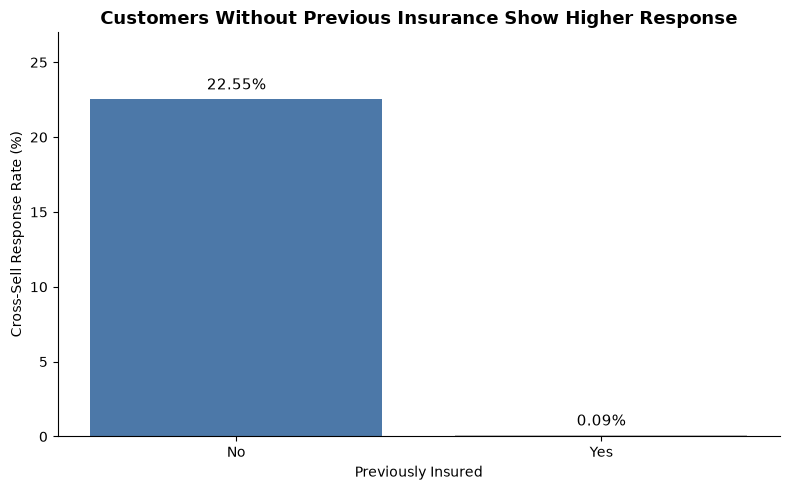

In [109]:
fig, ax = plt.subplots(figsize=(8, 5))

colors = ["#4C78A8", "#BDBDBD"]

bars = ax.bar(
    previous_insurance_response["Previously_Insured"].astype(str),
    previous_insurance_response["Response_Rate"],
    color=colors
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.4,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "Customers Without Previous Insurance Show Higher Response",
    fontsize=13,
    weight="bold"
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["No", "Yes"])
ax.set_xlabel("Previously Insured")
ax.set_ylabel("Cross-Sell Response Rate (%)")
ax.set_ylim(0, 27)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Customers who were not previously insured had a response rate of 22.55%, compared with 0.09% among customers who were previously insured.

This substantial difference suggests that previous insurance status is an important segmentation variable in the dataset.

Business implication: Customers without previous insurance may be a promising segment for cross-sell campaign evaluation.

Limitation: This is an observed association and does not establish causality.

Vehicle Age

In [110]:
vehicle_age_response = (
    df_clean.groupby("Vehicle_Age")["Response"]
    .mean()
    .mul(100)
    .reset_index(name="Response_Rate")
)

vehicle_age_response

,Vehicle_Age,Response_Rate
0,1-2 Year,17.375547
1,< 1 Year,4.370517
2,> 2 Years,29.374649


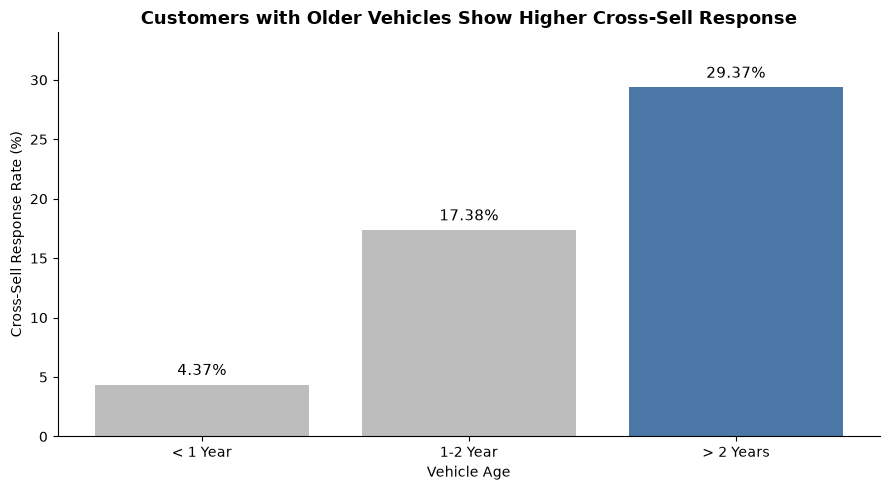

In [111]:
fig, ax = plt.subplots(figsize=(9, 5))

vehicle_age_order = ["< 1 Year", "1-2 Year", "> 2 Years"]

vehicle_age_response["Vehicle_Age"] = pd.Categorical(
    vehicle_age_response["Vehicle_Age"],
    categories=vehicle_age_order,
    ordered=True
)

vehicle_age_response = vehicle_age_response.sort_values("Vehicle_Age")

colors = ["#BDBDBD", "#BDBDBD", "#4C78A8"]

bars = ax.bar(
    vehicle_age_response["Vehicle_Age"].astype(str),
    vehicle_age_response["Response_Rate"],
    color=colors
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

ax.set_title(
    "Customers with Older Vehicles Show Higher Cross-Sell Response",
    fontsize=13,
    weight="bold"
)

ax.set_xlabel("Vehicle Age")
ax.set_ylabel("Cross-Sell Response Rate (%)")
ax.set_ylim(0, 34)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()